## Full code

In [2]:
import easyocr
import google.generativeai as genai
from PIL import Image, ImageEnhance, ImageOps
import numpy as np
from typing import List, Dict, Tuple, Union, Optional, Any
import os
from pathlib import Path
import logging
import json
from datetime import datetime

# Setup logging (UTF-8 safell)
logging.basicConfig(level=logging.INFO, encoding="utf-8")
logger = logging.getLogger(__name__)


class HybridOCR:
    """
    Hybrid OCR pipeline:
    1. EasyOCR (fast, local, good for most cases)
    2. If average/min confidence < threshold → fallback to Gemini (high accuracy, multilingual, RTL-aware)
    Fully modular, batch-ready, Arabic/English/mixed + RTL support, UTF-8 everywhere.
    """

    def __init__(
        self,
        easyocr_langs: List[str] = ["ar", "en"],
        confidence_threshold: float = 0.8,
        use_min_confidence: bool = False,
        gemini_model: str = "gemini-2.5-flash",  # fastest & cheapest as of 2026
        gpu: bool = True,  # set False on CPU-only machines
    ) -> None:
        # EasyOCR reader loaded ONCE (expensive operation)
        self.reader = easyocr.Reader(easyocr_langs, gpu=gpu)
        # Gemini setup
        api_key = os.getenv("GEMINI_API_KEY")
        if not api_key:
            raise ValueError("GEMINI_API_KEY environment variable must be set")
        genai.configure(api_key=api_key)
        self.model = genai.GenerativeModel(gemini_model)

        self.threshold = confidence_threshold
        self.use_min = use_min_confidence
        logger.info(
            f"HybridOCR initialized | langs={easyocr_langs} | threshold={confidence_threshold} "
            f"| model={gemini_model} | GPU={gpu}"
        )
    
    def preprocess_image( image: Union[str, Path, np.ndarray, Image.Image], apply_grey: bool) -> Image.Image:
        """Light preprocessing (contrast boost) to improve OCR accuracy on both engines."""
        if isinstance(image, (str, Path)):
            img = Image.open(image).convert("RGB")
        elif isinstance(image, np.ndarray):
            img = Image.fromarray(image).convert("RGB")
        elif isinstance(image, Image.Image):
            img = image.convert("RGB")
        else:
            raise ValueError(f"Unsupported image type: {type(image)}")
        
        # resize first 
        print(f"img.width = {img.width}")
        img = img.resize((img.width * 2, img.height * 2), Image.BICUBIC)
    
        if apply_grey:
            # convert to grayscale
            img = img.convert("L")
          
        # Boost contrast – helps especially with Arabic script and low-quality scans
        img = ImageOps.exif_transpose(img) # Reads EXIF tag Orientation
        enhancer = ImageEnhance.Contrast(img) 
        return enhancer.enhance(2)

    def run_easyocr(self, image: Union[str, Path, np.ndarray, Image.Image]) -> Tuple[str, List[float]]:
        """Run EasyOCR → return joined text + raw confidence scores per detection."""
        pil_img = self.preprocess_image(image,apply_grey=True)
        # EasyOCR works directly on numpy arrays
        result = self.reader.readtext(np.array(pil_img), detail=1, paragraph=False)

        if not result:
            return "", []

        # Sort detections by vertical position (top-left y) for correct top-to-bottom reading order
        # (critical for mixed LTR/RTL documents)
        sorted_result = sorted(result, key=lambda x: x[0][0][1])  # y-coordinate of top-left corner

        texts = [text for _, text, _ in sorted_result]
        confidences = [float(prob) for _, _, prob in sorted_result]

        combined_text = "\n".join(texts)  # preserves line/paragraph separation
        return combined_text, confidences

    def evaluate_confidence(self, confidences: List[float]) -> bool:
        """Return True if confidence meets threshold (average or minimum)."""
        if not confidences:
            return False
        metric = min(confidences) if self.use_min else (sum(confidences) / len(confidences))
        return metric >= self.threshold

    def run_gemini(self, image: Union[str, Path, np.ndarray, Image.Image], easyocr_text: str = "") -> str:
        """Gemini fallback with explicit prompt for multilingual + RTL correctness."""
        pil_img = self.preprocess_image(image,apply_grey = False)

        prompt = (
            "You are an expert OCR system specialized in accurate text extraction.\n"
            "Extract ALL visible text from the image exactly as it appears.\n"
            "- Support mixed Arabic and English text perfectly.\n"
            "- Preserve the original reading order and layout (very important for RTL Arabic).\n"
            "- Output the text in clean, well-formatted paragraphs or lines.\n"
            "- Do not add explanations, summaries, or extra text. ONLY output the extracted text.\n"
            "- Maintain proper Unicode and text directionality.\n\n"
        )

        try:
            response = self.model.generate_content([prompt, pil_img])
            return response.text.strip()
        except Exception as e:  # Gemini errors (rate limit, timeout, etc.)
            logger.error(f"Gemini API error: {e}")
            return easyocr_text  # graceful fallback to EasyOCR result

    def _log_low_confidence(
        self,
        image_id: str,
        easy_text: str,
        gemini_text: str,
        avg_conf: float,
        image_ref: str,
    ) -> None:
        """Log low-confidence cases to JSONL for future analysis / model improvement."""
        log_entry = {
            "timestamp": datetime.now().isoformat(),
            "image_id": image_id,
            "image_ref": image_ref,
            "easyocr_text": easy_text,
            "gemini_text": gemini_text,
            "easyocr_avg_conf": round(avg_conf, 4),
        }
        log_file = "low_confidence_ocr_log.jsonl"
        with open(log_file, "a", encoding="utf-8") as f:
            f.write(json.dumps(log_entry, ensure_ascii=False) + "\n")
        logger.info(f"Logged low-confidence case → {log_file} (image: {image_id})")

    def process_image(
        self, image_input: Union[str, Path, np.ndarray, Image.Image], image_id: Optional[str] = None
    ) -> Dict[str, Any]:
        """Main single-image pipeline (EasyOCR → optional Gemini)."""
        if image_id is None:
            image_id = f"img_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"

        # Stage 1: EasyOCR
        easy_text, confs = self.run_easyocr(image_input)
        avg_conf = sum(confs) / len(confs) if confs else 0.0

        result = {
            "text": easy_text,
            "source": "easyocr",
            "confidence": round(avg_conf, 4),
            "raw_confidences": confs,
            "image_id": image_id,
        }

        # Stage 2: Confidence check
        if self.evaluate_confidence(confs):
            logger.info(f"✅ High-confidence EasyOCR result for {image_id} (conf={avg_conf:.3f})")
            return result

        # Stage 3: Gemini fallback
        logger.warning(f"⚠️ Low confidence ({avg_conf:.3f}). Falling back to Gemini for {image_id}")
        gemini_text = self.run_gemini(image_input, easy_text)

        # Log the case (both results + image reference) for future improvement
        image_ref = str(image_input) if isinstance(image_input, (str, Path)) else "in-memory-image"
        self._log_low_confidence(image_id, easy_text, gemini_text, avg_conf, image_ref)

        result.update(
            {
                "text": gemini_text,
                "source": "gemini",
                "confidence": None,  # Gemini doesn't return numeric confidence
                "raw_confidences": confs,
            }
        )
        return result

    def process_batch(
        self,
        image_inputs: List[Union[str, Path, np.ndarray, Image.Image]],
        image_ids: Optional[List[str]] = None,
    ) -> List[Dict[str, Any]]:
        """Batch processing (sequential – safe for Gemini rate limits)."""
        if image_ids is None:
            image_ids = [f"batch_{i}" for i in range(len(image_inputs))]
        if len(image_ids) != len(image_inputs):
            raise ValueError("image_ids length must match image_inputs")

        results = []
        for img, iid in zip(image_inputs, image_ids):
            results.append(self.process_image(img, iid))
        return results

/usr/local/lib/python3.12/dist-packages/wrapt/importer.py:223: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  self.__wrapped__.exec_module(module)


## Testing Methods

### Preprocess (orientation correction and contrast)

In [9]:
import cv2
def preprocess_image( image: Union[str, Path, np.ndarray, Image.Image], apply_grey: bool) -> Image.Image:
    """Light preprocessing (contrast boost) to improve OCR accuracy on both engines."""
    if isinstance(image, (str, Path)):
        img = Image.open(image).convert("RGB")
    elif isinstance(image, np.ndarray):
        img = Image.fromarray(image).convert("RGB")
    elif isinstance(image, Image.Image):
        img = image.convert("RGB")
    else:
        raise ValueError(f"Unsupported image type: {type(image)}")
    
    # resize first (important)
    print(f"img.width = {img.width}")
    img = img.resize((int(img.width * 1.5), int(img.height * 1.5)), Image.BICUBIC)

    if apply_grey:
        # convert to grayscale
        img = img.convert("L")
  
    # Boost contrast – helps especially with Arabic script and low-quality scans
    img = ImageOps.exif_transpose(img) # Reads EXIF tag Orientation
    enhancer = ImageEnhance.Contrast(img) 
    return enhancer.enhance(2)


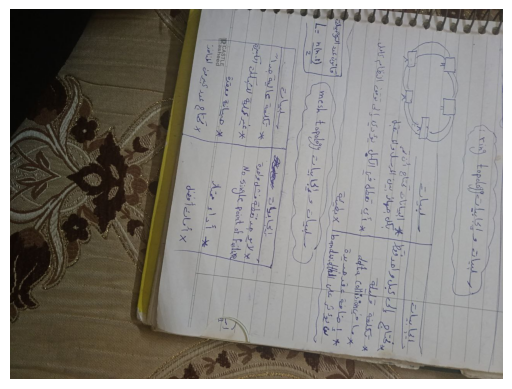

inhanced
img.width = 1280


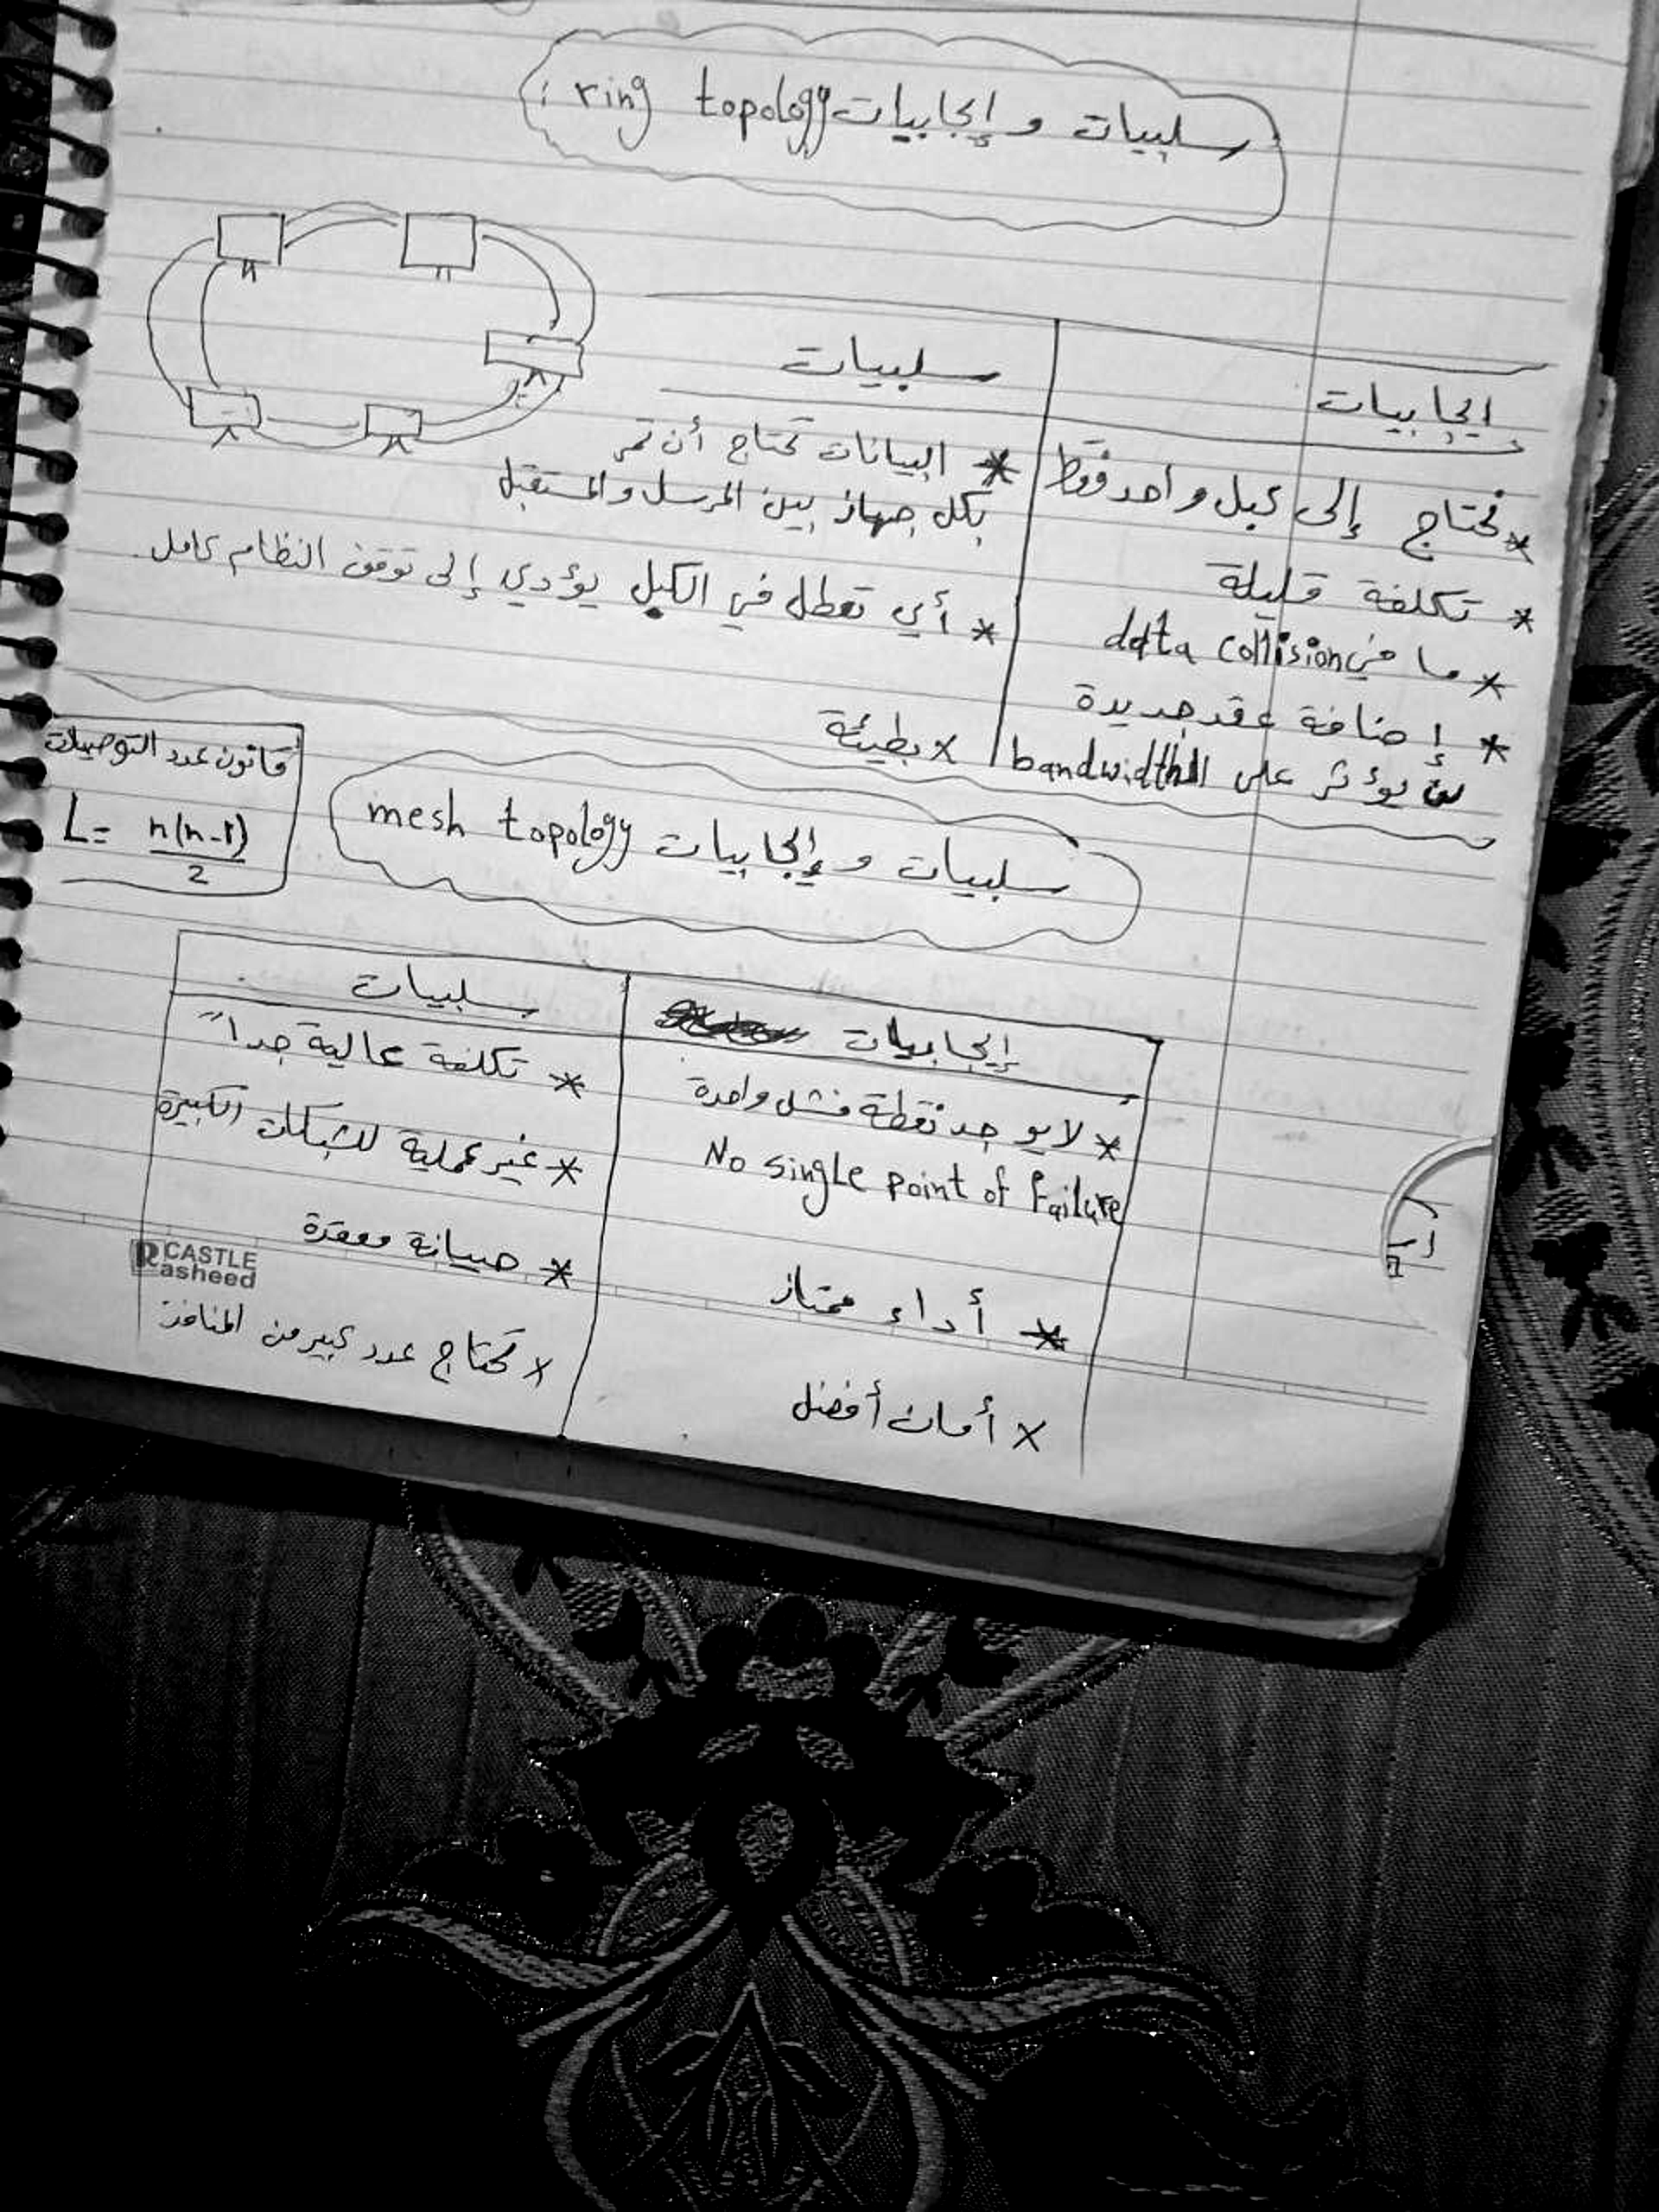

In [19]:
import matplotlib.pyplot as plt
from PIL import Image

image = '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Sample/images/3.jpg'
img = Image.open(image).convert("RGB")
plt.imshow(img)
plt.axis('off') # Hide axes
plt.show()

print('inhanced')
preprocess_image(image,apply_grey=True)

In [65]:
# import matplotlib.pyplot as plt
# from PIL import Image

# image = '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Sample/images/3.jpg'
# img = Image.open(image).convert("RGB")
# plt.imshow(img)
# plt.axis('off') # Hide axes
# plt.show()

# print('inhanced using prepocess_image_v2')
# preprocess_image_v2(image)

### run ocr

In [6]:
reader = easyocr.Reader(['ar','en'], gpu=False)

Progress: |██████████████████████████████████████████████████| 100.0% Complete

INFO:easyocr.easyocr:Download complete.


In [66]:
def run_easyocr(image: Union[str, Path, np.ndarray, Image.Image]) -> Tuple[str, List[float]]:
    """Run EasyOCR → return joined text + raw confidence scores per detection."""
    pil_img = preprocess_image(image)
    # EasyOCR works directly on numpy arrays
    result = reader.readtext(np.array(pil_img), detail=1, paragraph=False)
    if not result:
        return "", []
    # Sort detections by vertical position (top-left y) for correct top-to-bottom reading order
    # (critical for mixed LTR/RTL documents)
    sorted_result = sorted(result, key=lambda x: x[0][0][1])  # y-coordinate of top-left corner
    texts = [text for _, text, _ in sorted_result]
    confidences = [float(prob) for _, _, prob in sorted_result]
    combined_text = "\n".join(texts)  # preserves line/paragraph separation
    return combined_text, confidences

In [67]:
text, confidences = run_easyocr(image)

In [68]:
print(text)

-ap0لبيات , إجابيات 9قا
٩»٢١
ببيات
احا
سات
اليانات
سا&
أن س
امد ودلا
ركل جهاد ري المرسل والستفبلا
كبل م
الى
نتاج
تومى الظامم كافل
روئ دل
اك
تكلفه حليله
تعطل ح اآل
{ x
aqla
*
Coاlf>fonعي
ما
X
عقدمد ده
ء صاعء
x بصله
قانون عدد التوجيلات
bandu athll
X
لول ك
عائ
لا
topaloy
Ie5n
L-
ابا بيات
ااتحد
ببيات
?
2
لببات
را برات
عالمة
مر
تلمو
مد تعمة نثل رامدة
50)
لشلان
* لالو
Uد عرعل
٨٠
Sivale Pait هf
filR
تعفرة
مانه
ICASTLE
ممار
ashead
٢داء
الماءر
عرد كببرعن
رما &
x امات ٦ عصل


In [69]:
def weighted_confidence(results):
    total = 0
    weight_sum = 0
    (text,confidences) = results
    text_list = text.split('\n')

    for (text, conf) in zip(text_list, confidences):
        weight = len(text)
        total += conf * weight
        weight_sum += weight

    return total / weight_sum if weight_sum > 0 else 0
    
print(f'the average confidence is {weighted_confidence((text,confidences))}')
if (sum(confidences)/len(confidences)) < 0.8:
    print('very hard image we need to use VLLM')

the average confidence is 0.27808947392181216
very hard image we need to use VLLM


In [58]:
print(confidences)

[0.15041294791805665, 0.18992218801714666, 0.8525004252559041, 0.5207643191094317, 0.7253911318670448, 0.15703414380550385, 0.24787565225622657, 0.4679618610195066, 0.2047487809749556, 0.7378098964691162, 0.4355717892599619, 0.15153900003870135, 0.06364681008588936, 0.24362403329894108, 0.18744374410669068, 0.10731487603307326, 0.7106107473373413, 0.7342697511965505, 0.491836510903821, 0.4724057614803314, 0.5421806879210921, 0.14293357729911804, 0.5245810863087605, 0.12654411640601781, 0.8814436603315698, 0.27754603643757036, 0.12138176039503962, 0.519856687514303, 0.18719801850588333, 0.23734101709978592, 0.24685884040857164, 0.24829342860858106, 0.23617248007582603, 0.21261195146121425, 0.14854500691587177, 0.30974354134347243, 0.25110888481140137, 0.4607375059709765, 0.06099150989559262, 0.682438337959902, 0.11154158137566128, 0.9558225726218303, 0.25465139427387434, 0.16564864109203434, 0.2678753977882719, 0.6276029514085142, 0.13887029648132568, 0.13652090995164354, 0.276169681023

Let's try a simpler image

In [72]:
image = '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Sample/images/0.png'
text, confidences = run_easyocr(image)
print(text)

٥٥٧٥، ٥١ ،٤٨، ٢١٥
ما
٥ ٥
<٨
 ٥
5٨٥٢٤
ng document Save time by reading a summary using Al Assistant 
View Summ
and Pmesy Polia
٧٤
he Adobe Iems cf
Ring:
Each device is connected to two neighbors,
|00p.
forming a closed
Data travels in one
direction, and if one device fails  it can break
the entire network
prepared by Dr
Imad
M
Damascus
university 2025/2026


In [74]:
print(f'the average confidence is {weighted_confidence((text,confidences))}')
if (sum(confidences)/len(confidences)) < 0.8:
    print('very hard image we need to use VLLM')

the average confidence is 0.6087528023708134
very hard image we need to use VLLM


### Test run Gemini

I am going to compare two models on four images to see wich one perform better. The first one is a smaller open source model from google **"gemma-4-31b-it"** with 1500 Request Per Day limit. The second one is **"gemini-3.1-flash-lite-preview"** with 500 Request Per Day limit.

In [34]:
vlm_test_images = [
    '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Sample/images/0.png',
    '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Sample/images/2.png',
    '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Sample/images/3.jpg',
    '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Sample/images/6.png'  
]

### Adding context to Gemini
I am going to refine the code to add context to gemini so it can easily connect between slides/images and gather better grounded understanding

In [4]:
from typing import Union, List
from pathlib import Path
import PIL.Image
import numpy as np

def run_gemini_batch(
    images: List[PIL.Image.Image], 
    subject: str, 
    lecture_title: str, 
    history: List[str]
) -> str:
    """
    Processes a batch of images (3) with temporal context and visual grounding.
    """
    # 1. Prepare Context (Only last 2 history entries to avoid prompt bloat)
    recent_history = "\n---\n".join(history[-2:]) if history else "Start of lecture."

    # 2. Construct the Systematic Prompt
    prompt = (
        f"SYSTEM: You are an academic transcription expert for {subject}.\n"
        f"LECTURE: {lecture_title}\n"
        f"RECENT CONTEXT: {recent_history}\n\n"
        "TASK: Analyze the provided images in sequence. For EACH image:\n"
        "1. EXTRACTED TEXT: All text exactly as shown. Support Arabic/English RTL.\n"
        "2. VISUALS: Detect every diagram, sketch, or complex chart. For each, provide:\n"
        "   - BOX: [ymin, xmin, ymax, xmax] (normalized 0-1000 coordinates).\n"
        "   - DESCRIPTION: Formal explanation of the visual's meaning.\n\n"
        "3. For the images in this batch, number them as SLIDE_1, SLIDE_2, SLIDE_3 respectively.\n"
        "OUTPUT FORMAT (STRICT):\n"
        "### SLIDE_[N] ###\n"
        "## TEXT ##\n[Raw Text]\n"
        "## VISUALS ##\n"
        "#\nCOORD: [ymin, xmin, ymax, xmax]\nDESC: [Brief Description]\n#\n"
    )

    # Contents: Prompt + the list of images
    contents = [prompt] + images

    try:
        # NOTE: Using 'gemini-2.0-flash' for best batch/vision performance
        response = client.models.generate_content(
            model="gemini-2.0-flash", 
            contents=contents
        )
        return response.text.strip()
    except Exception as e:
        logger.error(f"Batch API error: {e}")
        return f"Error: {e}"

#### Testing "gemma-4-31b-it"

In [ ]:
all_extracted_data = []
images_history = []

# Your main processing loop
for img_path in vlm_test_images:
    # 1. Call the function (History is passed but not modified inside)
    result = run_gemini(img_path, subject, title, images_history)
    
    # 2. Check if the result is valid before "polluting" the history
    if not result.startswith("Error:"):
        # We append to the history here, in the main orchestrator
        images_history.append(result)
        all_extracted_data.append(result)
    else:
        # Log error but don't add "Error: 500" to the AI's memory
        logger.warning(f"Skipping history update for {img_path} due to error.")

# Now all_extracted_data is ready for the 'Blender' pass

In [31]:
run_gemini(image = '/kaggle/input/datasets/mahdiat11/wajeez-test-sample/Test_Sample/images/0.jpg',)

img.width = 1280


INFO:google_genai.models:AFC is enabled with max remote calls: 10.
INFO:httpx:HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.1-flash-live-preview:generateContent "HTTP/1.1 404 Not Found"
ERROR:__main__:Gemini API error: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'models/gemini-3.1-flash-live-preview is not found for API version v1beta, or is not supported for generateContent. Call ListModels to see the list of available models and their supported methods.', 'status': 'NOT_FOUND'}}


"404 NOT_FOUND. {'error': {'code': 404, 'message': 'models/gemini-3.1-flash-live-preview is not found for API version v1beta, or is not supported for generateContent. Call ListModels to see the list of available models and their supported methods.', 'status': 'NOT_FOUND'}}"

In [27]:
print('سلبيات وإيجابيات ring topology\n\nإيجابيات:\n* نحتاج إلى كبل واحد فقط\n* تكلفة قليلة\n* ما في data collision\n* إضافة عقد جديدة\nلن يؤثر على ال bandwidth\n\nسلبيات:\n* البيانات تحتاج أن تمر بكل جهاز بين المرسل والمستقبل\n* أي تعطل في الكبل يؤدي إلى توقف النظام كامل\n* بطيئة\n\nقانون عدد التوصيلات\n$L = \\frac{n(n-1)}{2}$\n\nسلبيات وإيجابيات mesh topology\n\nإيجابيات:\n* لا يوجد نقطة فشل واحدة\nNo single point of failure\n* أداء ممتاز\n* أمانه أفضل\n\nسلبيات:\n* تكلفة عالية جداً\n* غير عملية للشبكات الكبيرة\n* صيانة معقدة\n* تحتاج عدد كبير من المنافذ\n\nCASTLE Rasheed')

سلبيات وإيجابيات ring topology

إيجابيات:
* نحتاج إلى كبل واحد فقط
* تكلفة قليلة
* ما في data collision
* إضافة عقد جديدة
لن يؤثر على ال bandwidth

سلبيات:
* البيانات تحتاج أن تمر بكل جهاز بين المرسل والمستقبل
* أي تعطل في الكبل يؤدي إلى توقف النظام كامل
* بطيئة

قانون عدد التوصيلات
$L = \frac{n(n-1)}{2}$

سلبيات وإيجابيات mesh topology

إيجابيات:
* لا يوجد نقطة فشل واحدة
No single point of failure
* أداء ممتاز
* أمانه أفضل

سلبيات:
* تكلفة عالية جداً
* غير عملية للشبكات الكبيرة
* صيانة معقدة
* تحتاج عدد كبير من المنافذ

CASTLE Rasheed


### Running

In [1]:

# # ========================== USAGE EXAMPLE ==========================
# if __name__ == "__main__":
#     # Initialize once (reader + model stay in memory)
#     ocr = HybridOCR(confidence_threshold=0.8, gpu=True)

#     # Single image
#     result = ocr.process_image("path/to/sample_image.jpg")
#     print(f"Source: {result['source']} | Confidence: {result.get('confidence')}")
#     print("Extracted text:\n" + result["text"])

#     # Batch example
#     # batch_results = ocr.process_batch(["img1.jpg", "img2.jpg", "img3.jpg"])